# Imports

In [2]:
import numpy as np
from scipy.optimize import minimize
from scipy.optimize import NonlinearConstraint
import seaborn as sns 
import matplotlib.pyplot as plt

# Data Loading

In [3]:
data_folder_path = "../../../../connect_tome/data/flywire_fafb"
connections_path = f'{data_folder_path}/connections_princeton_no_threshold.csv.gz'
cell_types_path = f'{data_folder_path}/consolidated_cell_types.csv.gz'

# Model

$\begin{gather}
\tau_x \dot{y}_i + y_i = x_i + \sum_j W_{ij}z_j \\
\tau_y \dot{z_j} + z_j = \sum_i M_{ji}y_i \\
y^{\infty} = x^{\infty} + Wz^{\infty} \\
y^{\infty} = x^{\infty} + WMy^{\infty} \\
y^{\infty} = (I - WM)^{-1}x^{\infty} 
\end{gather}$

Assume $\langle x \rangle = 0$. We can further simplify the optimization problem via the Sherman-Morrison rank 1 formula:
$(I - wm^T)^{-1} = I + \frac{wm^T}{1 - m^Tw}.$ If we define $v = m/(1 - m^Tw)$ then we also see that problem becomes $y^{\infty} = (I + wv^T)x^{\infty}.$

The stability constraint is that $m^Tw < 1$ which we convert to $w^Tv + 1 > 0$. 

Instead of the covariance as an objective, we fit with the objective of the trace normalized covariance - $||I - n\Sigma_Y / tr(\Sigma_Y)||.$


In [32]:
# First pass, weight matrix is a rank 1 outer product. Minimizing covariance. 

def unpack(params, n):
    return params[:n], params[n:]

def forward(input_data, w, v):
    """Gets, X, W, M and returns Y in steady state.

    Args:
        input_data: neurons x samples 
        w: (neurons,)
        v: (neurons,)

    Returns:
        y: neurons x neurons
    
    """
    state_dim = input_data.shape[0]
    matrix = np.eye(state_dim) + np.outer(w, v)
    return matrix @ input_data

def residual(params, input_data):
    """Calculates covariance residual
    
    Args:
        params: (2*neurons,)
        input_data: neurons x neurons
    
    Returns:
        residuals: (neurons**2,)
    """
    state_dim = input_data.shape[0]
    w, v = unpack(params, n=state_dim)

    outputs = forward(input_data, w, v)
    output_cov = np.cov(outputs)

    return np.eye(state_dim) - output_cov / (np.trace(output_cov) / state_dim)

def obj_fun(params, input_data):
    return 0.5 * np.linalg.norm(residual(params, input_data))**2

def gain_const(params):
    """Closed loop gain control (1 + w^Tv > 0)"""
    w,v = unpack(params, n=len(params) // 2)
    return 1 + w @ v


In [33]:
# Synthetic Data - generate data from a rank one perturbation
n_samples = 100000
n_neurons = 14
c = 0.5
toy_cov = np.eye(n_neurons) + c * np.outer(np.ones(n_neurons), np.ones(n_neurons))
toy_data = np.random.multivariate_normal(mean=np.zeros(n_neurons), cov=toy_cov, size=n_samples).T

# Performing the fit 
x_0 = np.random.standard_normal(n_neurons * 2)
nonlin_constraint = NonlinearConstraint(gain_const, 1e-12, np.inf)

res = minimize(obj_fun, x_0, args=toy_data, constraints=nonlin_constraint)

floor: 69.24957579229361  fit: 0.0006803539990956942
m.w: -1.7954905324091643  reference: -1.8284271247461903
1 + v.w: 0.35771897218274473  reference: 0.35355339059327373


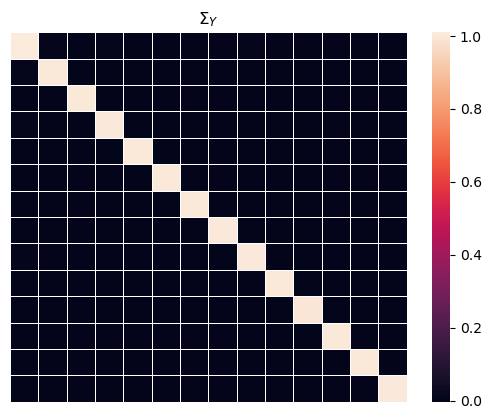

In [51]:
# Checking constraint
w, v = unpack(res.x, n_neurons)
m = v / (1 + v @ w)
print("floor:", obj_fun(x_0, toy_data), " fit:", res.fun)
print("m.w:", m @ w, " reference:", 1 - np.sqrt(1 + n_neurons * c))
print('1 + v.w:', 1 + v@w, ' reference:', 1 / np.sqrt(1 + n_neurons * c))

# Visually inspecting the result
a = np.eye(n_neurons) + np.outer(w, v)
sns.heatmap(a @ toy_cov @ a.T, linewidths=0.4) 
plt.title(r'$\Sigma_Y$')
plt.xticks([]); plt.yticks([]);

# Does the connectome do whitening? 